Exploratory Data Analysis 
Roles to Explore:

In [12]:
import ast
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt
import seaborn as sns

#Loading Data
dataset= load_dataset("lukebarousse/data_jobs")
df=dataset['train'].to_pandas()

# Data Cleanup
df['job-posted_date']=pd.to_datetime(df['job_posted_date'])
df['job_skills']=df['job_skills'].apply(lambda x : ast.literal_eval(x) if pd.notna(x) else x)


Filter for US Data Analyst roles

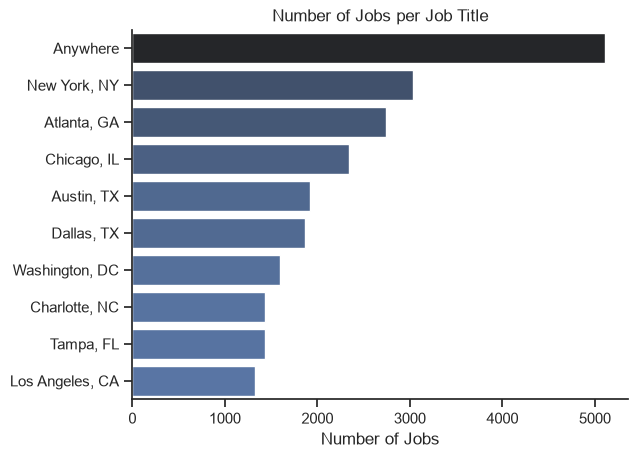

In [17]:
df_DA_US=df[(df['job_country']=='United States') & (df['job_title_short']=='Data Analyst')]
df_plot=df_DA_US['job_location'].value_counts().head(10).to_frame()
sns.set_theme(style='ticks')
sns.barplot(data=df_plot, x='count', y='job_location',hue='count', palette='dark:b_r',legend=False)
sns.despine()
plt.title('Number of Jobs per Job Title')
plt.xlabel('Number of Jobs')
plt.ylabel('')
plt.show()

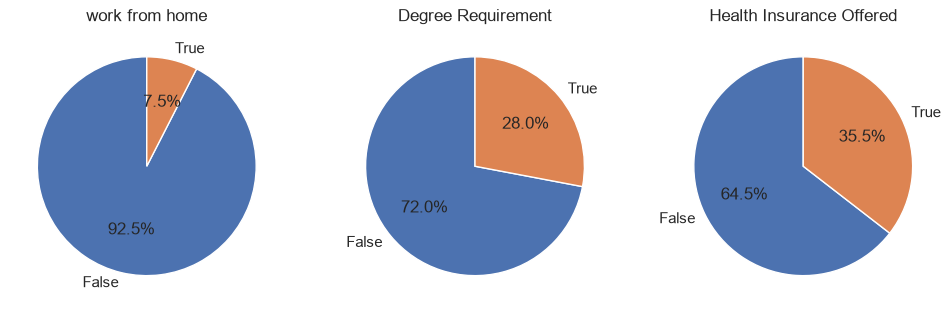

In [ ]:
fig,ax =plt.subplots(1,3)
fig.set_size_inches((12,5))

dict_column={ 
    'job_work_from_home': 'work from Home Offered',
    'job_no_degree_mention': 'Degree Requirement',
    'job_health_insurance': 'Health Insurance Offered'
}

for i,(column,title) in enumerate(dict_column.items()):
        ax[i].pie(df_DA_US[column].value_counts(), labels=['False','True'],startangle=90,autopct="%1.1f%%")
        ax[i].set_title(title)

plt.show()

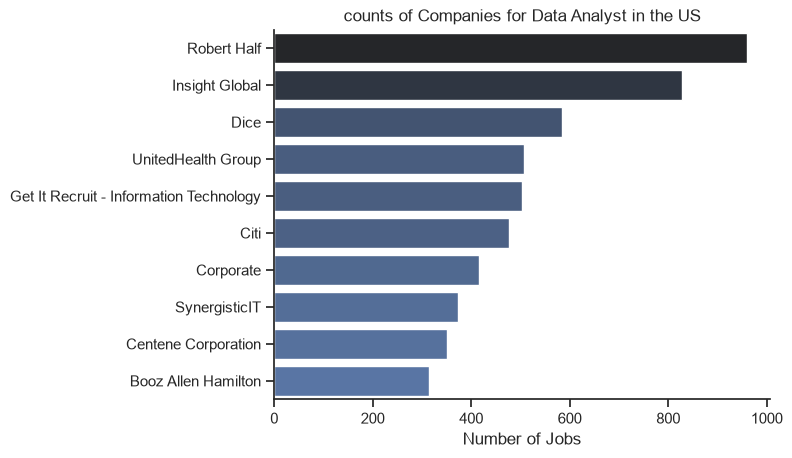

In [25]:

df_plot=df_DA_US['company_name'].value_counts().head(10).to_frame()
sns.set_theme(style='ticks')
sns.barplot(data=df_plot, x='count', y='company_name',hue='count', palette='dark:b_r',legend=False)
sns.despine()
plt.title('counts of Companies for Data Analyst in the US')
plt.xlabel('Number of Jobs')
plt.ylabel('')
plt.show()